# Chapter 2 — One Real State: North Carolina, 2016

In Chapter 1 we rigged a toy map with 25 voters. Now we do the same three measurements on a real state with real votes.

**Why North Carolina?** In 2016 it had 13 congressional districts, all of them contested, and its map is one of the most studied in America. Democrats won about 47% of the statewide congressional vote — and only 3 of the 13 seats. That gap is the story.

## The three metrics, in plain words

- **Efficiency gap:** the difference in wasted votes between the parties, as a share of all votes. Wasted = votes for the loser + surplus votes for the winner above half. Near 0% = fair; beyond roughly 7–8%, researchers get suspicious.
- **Mean–median difference:** the average district's Democratic vote share minus the median district's. If the median district is much more Republican than the average, Democratic voters are packed into a few districts.
- **Partisan bias (uniform swing):** imagine shifting every district by the same amount until the statewide vote is exactly 50–50. What share of seats would Democrats win then? If it isn't 50%, the map itself leans one way.

## Data

Princeton gerrymetrics' bundled congressional results file (public, free). On Colab the download cell below fetches it; locally it is already in `data/raw/`.


In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q pandas matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

LOCAL = '../data/raw/congressional_election_results_post1948.csv'
URL = ('https://raw.githubusercontent.com/PrincetonUniversity/gerrymandertests/'
       'master/election_data/congressional_election_results_post1948.csv')

if os.path.exists(LOCAL):
    path = LOCAL
    print('Using local file:', LOCAL)
else:
    path = URL
    print('Local file not found; downloading from Princeton gerrymetrics repo.')

df = pd.read_csv(path)
print('Columns:', list(df.columns))
print('Years covered:', int(df['Year'].min()), '-', int(df['Year'].max()))
print('Rows:', len(df))

Using local file: ../data/raw/congressional_election_results_post1948.csv
Columns: ['State', 'Year', 'District', 'Dem Votes', 'GOP Votes', 'D Voteshare', 'Incumbent', 'Party']
Years covered: 1948 - 2018
Rows: 15663


In [3]:
# North Carolina, 2016: 13 districts, all contested
nc = df[(df['State'] == 'NC') & (df['Year'] == 2016)].copy()
nc = nc.sort_values('District')
print(nc[['District', 'Dem Votes', 'GOP Votes', 'D Voteshare', 'Party']].to_string(index=False))
print()
print('Districts:', len(nc))
print('Democratic vote share statewide:',
      round(nc['Dem Votes'].sum() / (nc['Dem Votes'].sum() + nc['GOP Votes'].sum()) * 100, 1), '%')
print('Democratic seats:', int((nc['Party'] == 'D').sum()), 'of', len(nc))

 District  Dem Votes  GOP Votes  D Voteshare Party
        1   240661.0   101567.0     0.703218     D
        2   169082.0   221485.0     0.432914     R
        3   106170.0   217531.0     0.327988     R
        4   279380.0   130161.0     0.682178     D
        5   147887.0   207625.0     0.415983     R
        6   143167.0   207983.0     0.407709     R
        7   135905.0   211801.0     0.390862     R
        8   133182.0   189863.0     0.412271     R
        9   139041.0   193452.0     0.418177     R
       10   128919.0   220825.0     0.368610     R
       11   129103.0   230405.0     0.359110     R
       12   234115.0   115185.0     0.670240     D
       13   156049.0   199443.0     0.438966     R

Districts: 13
Democratic vote share statewide: 46.7 %
Democratic seats: 3 of 13


## Metric 1 — Efficiency gap

For each district: the winner's wasted votes are the votes above half of the district's two-party total; the loser's wasted votes are all of their votes. Add them up per party and take the difference, divided by total votes. We sign it so that **positive favors Democrats, negative favors Republicans**.


In [4]:
def efficiency_gap(frame):
    wasted_d = 0.0
    wasted_r = 0.0
    total = 0.0
    for _, r in frame.iterrows():
        d = r['Dem Votes']
        g = r['GOP Votes']
        tot = d + g
        total += tot
        if d > g:  # Democrats win
            wasted_d += d - tot / 2
            wasted_r += g
        else:      # Republicans win
            wasted_r += g - tot / 2
            wasted_d += d
    return (wasted_r - wasted_d) / total


eg = efficiency_gap(nc)
print(f'Efficiency gap (NC 2016): {eg * 100:.1f}%')
print()
print('Plain-English sentence: the map wastes far more Democratic votes than Republican')
print('votes, giving Republicans an efficiency-gap advantage of about',
      f'{abs(eg) * 100:.0f} percentage points.')

Efficiency gap (NC 2016): -19.4%

Plain-English sentence: the map wastes far more Democratic votes than Republican
votes, giving Republicans an efficiency-gap advantage of about 19 percentage points.


## Metric 2 — Mean–median difference

Take the Democratic vote share in each district. The **mean** is the ordinary average. The **median** is the middle district when you line them up. If the median is well below the mean, Democratic voters are packed into a few landslide districts while most districts lean Republican.


In [5]:
shares = nc['D Voteshare']
mean_share = shares.mean()
median_share = shares.median()
mm = mean_share - median_share
print(f'Mean Democratic share:   {mean_share * 100:.1f}%')
print(f'Median Democratic share: {median_share * 100:.1f}%')
print(f'Mean-median difference:  {mm * 100:.1f} points')
print()
print('Plain-English sentence: the typical (median) district is about',
      f'{abs(mm) * 100:.0f} points more Republican than the average district,',
      'because Democratic voters are packed into a few districts.')

Mean Democratic share:   46.4%
Median Democratic share: 41.6%
Mean-median difference:  4.8 points

Plain-English sentence: the typical (median) district is about 5 points more Republican than the average district, because Democratic voters are packed into a few districts.


## Metric 3 — Partisan bias (uniform swing)

Shift every district's Democratic share by the same amount until the statewide vote is exactly 50–50, then count how many seats Democrats would win. In a neutral map that should be half the seats. Anything else is the map's built-in lean.


In [6]:
statewide_d = nc['Dem Votes'].sum() / (nc['Dem Votes'].sum() + nc['GOP Votes'].sum())
shift = 0.5 - statewide_d
swung = nc['D Voteshare'] + shift
d_seats_swung = int((swung > 0.5).sum())
bias = d_seats_swung / len(nc) - 0.5
print(f'Statewide Democratic share: {statewide_d * 100:.1f}%')
print(f'Uniform shift applied: {shift * 100:+.1f} points')
print(f'Seats Democrats would win at 50-50: {d_seats_swung} of {len(nc)}')
print(f'Partisan bias: {bias * 100:.1f} points')
print()
print('Plain-English sentence: even with exactly half the votes, Democrats would win only',
      f'{d_seats_swung} of {len(nc)} seats on this map — the map itself leans Republican.')

Statewide Democratic share: 46.7%
Uniform shift applied: +3.3 points
Seats Democrats would win at 50-50: 3 of 13
Partisan bias: -26.9 points

Plain-English sentence: even with exactly half the votes, Democrats would win only 3 of 13 seats on this map — the map itself leans Republican.


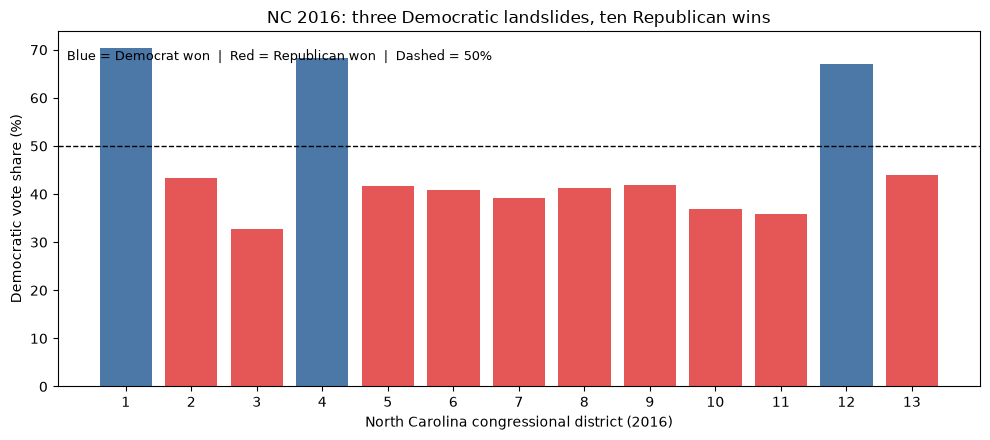

Chart saved to charts/phase2_nc2016_voteshare.png


In [7]:
# Chart: Democratic vote share by district, with the 50% win line
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = ['#4c78a8' if p == 'D' else '#e45756' for p in nc['Party']]
ax.bar(nc['District'].astype(str), nc['D Voteshare'] * 100, color=colors)
ax.axhline(50, color='black', linewidth=1, linestyle='--')
ax.set_xlabel('North Carolina congressional district (2016)')
ax.set_ylabel('Democratic vote share (%)')
ax.set_title('NC 2016: three Democratic landslides, ten Republican wins')
ax.text(0.01, 0.95, 'Blue = Democrat won  |  Red = Republican won  |  Dashed = 50%',
        transform=ax.transAxes, va='top', fontsize=9)
plt.tight_layout()
plt.savefig('../charts/phase2_nc2016_voteshare.png', dpi=150)
plt.show()
print('Chart saved to charts/phase2_nc2016_voteshare.png')

## Checkpoint — what you now know

- The same three ideas from the toy example, computed on real votes.
- North Carolina 2016: Democrats won ~47% of the vote and 3 of 13 seats — and all three metrics agree the map leaned Republican.
- One chart that shows the mechanism at a glance: three tall blue bars (packed Democratic wins) and ten red bars just over the line (cracked Republican wins).

Next chapter: we draw the maps themselves, and watch the lines move in 2016, 2020, and 2024.
